# Two summary figures — irradiated tumor and abscopal tumor (single cell, macrophage focus)

Built only from existing result tables; nothing is refit here.

| figure | message |
|---|---|
| **S1 — irradiated tumor** | PSCA shifts macrophages toward an interferon-stimulated, MHC-high, less lipid-TAM state. With RT, MHC-I/II tend to rise further (consistent, not significant). What RT changes measurably is a lower CD73 / adenosine axis in the same myeloid cells. |
| **S2 — abscopal tumor** | The one robust effect runs against an advantage (interferon loss). Leading evidence: lipid TAMs lose efferocytosis, NK cells look less inhibited, monocyte-recruiting chemokines rise, CD8 homing receptors rise with PSCA, and tumor-cell p53 / DNA-repair programs rise with PSCA. |

**Sources**
* `results/mhc_cytotox/`: `program_score_contrasts.csv` (exact relabelling), `exhaustion_sample_contrasts.csv`,
  `exhaustion_glmm.csv` and `chem_receptor_glmm.csv` (per-cell binomial GLMM).
* `results/rt_advantage/`: `tumour_state_rt_contrasts.csv`.
* `results/rt_advantage/specific_cell_type/macrophages/` (from notebook 01): `composition_per_sample.csv`,
  `composition_effects.csv`, `module_effects.csv`.

**Encoding, used in every panel**
* Orange = PSCA, blue = TAG72; filled = RT, open = no RT; circle = Tu1, square = Tu2.
* In the effect panels: orange = the RT effect within PSCA, blue = the RT effect within TAG72, black diamond =
  pooled over both CARs.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
MC, RA = PROJ/"results/mhc_cytotox", PROJ/"results/rt_advantage"
MAC = RA/"specific_cell_type/macrophages"
OUT = RA/"specific_cell_type/summary"; OUT.mkdir(parents=True, exist_ok=True)
for f_ in [MC/"program_score_contrasts.csv", MC/"exhaustion_sample_contrasts.csv", MC/"exhaustion_glmm.csv",
           MC/"chem_receptor_glmm.csv", RA/"tumour_state_rt_contrasts.csv", MAC/"composition_per_sample.csv",
           MAC/"composition_effects.csv", MAC/"module_effects.csv"]:
    assert f_.exists(), f"missing {f_} — run mhcCytotoxExhaustion, rtAdvantage/03 and specificCellTypeAnalysis/01 first"

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72 = "#eb6834", "#2a78d6"
S_GOOD, S_WARN, S_CRIT = "#0ca30c", "#fab219", "#d03b3b"
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8.2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
    "axes.facecolor": "white", "savefig.facecolor": "white", "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.dpi": 300, "text.color": INK})
NAME = {"IFN_stimulated_Mac": "M1-like (IFN-stim)", "M2_like_Mac": "M2-like", "Apoe_high_Mac": "M2: Apoe-high",
        "Arg1_high_Mac": "M2: Arg1-high", "Fn1_high_Mac": "M2: Fn1-high", "Intermediate_Mac": "Intermediate",
        "SPP1_TAM": "SPP1-TAM", "Classical_Mono": "Classical mono", "Nonclassical_Mono": "Patrolling mono", "cDC": "cDC"}


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return "<0.001" if p < 0.001 else (f"{p:.3f}" if p < 0.1 else f"{p:.2f}")


PSC = pd.read_csv(MC/"program_score_contrasts.csv")
EXS = pd.read_csv(MC/"exhaustion_sample_contrasts.csv")
EXG = pd.read_csv(MC/"exhaustion_glmm.csv")
CRG = pd.read_csv(MC/"chem_receptor_glmm.csv")
TST = pd.read_csv(RA/"tumour_state_rt_contrasts.csv")
CPS = pd.read_csv(MAC/"composition_per_sample.csv", index_col=0)
CPS["arm"] = CPS.arm.astype(str).str.replace("TAG72", "T72")
CEF = pd.read_csv(MAC/"composition_effects.csv")
MOD = pd.read_csv(MAC/"module_effects.csv")

## Plot helpers

In [2]:
def badge(ax, text, color, x=1.0, y=1.02, tc="white"):
    ax.text(x, y, text, transform=ax.transAxes, ha="right", va="bottom", fontsize=7.6, color=tc, weight="bold",
            bbox=dict(boxstyle="round,pad=0.28,rounding_size=0.25", fc=color, ec="none"))


def forest(ax, rows, xlabel, p_head="p", xlim=None):
    """rows: list of dicts with label, psca(est, lo, hi), tag(est, lo, hi), pooled(est, lo, hi) or None, p (text)."""
    for i, r in enumerate(rows):
        y = -i
        for key, col, off, mk in [("psca", C_PSCA, 0.18, "o"), ("tag", C_TAG72, 0.0, "o"), ("pooled", INK, -0.2, "D")]:
            v = r.get(key)
            if v is None or not np.isfinite(v[0]): continue
            est, lo, hi = v
            if np.isfinite(lo) and np.isfinite(hi):
                ax.plot([lo, hi], [y + off] * 2, color=col, lw=1.6 if key == "pooled" else 1.1, solid_capstyle="round")
            ax.plot(est, y + off, marker=mk, color=col, ms=6.5 if key == "pooled" else 6, mec="white", mew=0.8, zorder=3)
        ax.text(1.02, y, r["p"], transform=ax.get_yaxis_transform(), va="center", fontsize=7.6,
                color=INK, weight="bold" if r.get("bold") else "normal")
    ax.text(1.02, 0.62, p_head, transform=ax.get_yaxis_transform(), va="bottom", fontsize=7, color=MUTED, weight="bold")
    ax.axvline(0, color=INK2, lw=0.9)
    ax.set_yticks([-i for i in range(len(rows))]); ax.set_yticklabels([r["label"] for r in rows])
    ax.set_ylim(-len(rows) + 0.45, 0.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)
    if xlim: ax.set_xlim(*xlim)


def strip_car(ax, col, ylabel, title, p_text):
    d = CPS[CPS.arm.isin(["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"])]
    for x, car_arms, color in [(0, ["CyT72", "RTCyT72"], C_TAG72), (1, ["CyPSCA", "RTCyPSCA"], C_PSCA)]:
        sub = d[d.arm.isin(car_arms)]
        rng = np.random.default_rng(1)
        for _, r in sub.iterrows():
            rt = r.arm.startswith("RT")
            ax.scatter(x + rng.uniform(-0.17, 0.17), r[col], s=38, marker="o" if int(r.site) == 1 else "s",
                       facecolor=color if rt else "white", edgecolor=color, linewidth=1.4, zorder=3)
        ax.plot([x - 0.3, x + 0.3], [sub[col].mean()] * 2, color=INK, lw=1.8, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["TAG72", "PSCA"]); ax.set_xlim(-0.6, 1.6)
    ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_ylabel(ylabel); ax.set_title(title, loc="left", fontsize=9.4, pad=16)
    ax.text(0, 1.01, p_text, transform=ax.transAxes, fontsize=7.4, color=INK2, va="bottom")


def legend(fig, y=0.0, extra=()):
    h = [Line2D([], [], marker="o", ls="", mfc="white", mec=C_PSCA, mew=1.3, ms=7, label="PSCA, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec=C_PSCA, ms=7, label="PSCA + RT"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=C_TAG72, mew=1.3, ms=7, label="TAG72, no RT"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec=C_TAG72, ms=7, label="TAG72 + RT"),
         Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, ms=7, label="square = Tu2"),
         Line2D([], [], color=INK, lw=1.8, label="mean")] + list(extra)
    fig.legend(handles=h, loc="lower center", ncol=len(h), frameon=False, bbox_to_anchor=(0.5, y), fontsize=8)


def ceff(feature, denom, eff, part, k):
    d = CEF[(CEF.feature == feature) & (CEF.denominator == denom) & (CEF.effect == eff) & (CEF.part == part)]
    return d[k].iloc[0]


def mod(group, module, eff, part):
    d = MOD[(MOD.group == group) & (MOD.module == module) & (MOD.effect == eff) & (MOD.part == part)]
    return d.iloc[0] if len(d) else None

## Figure S1 — irradiated tumor

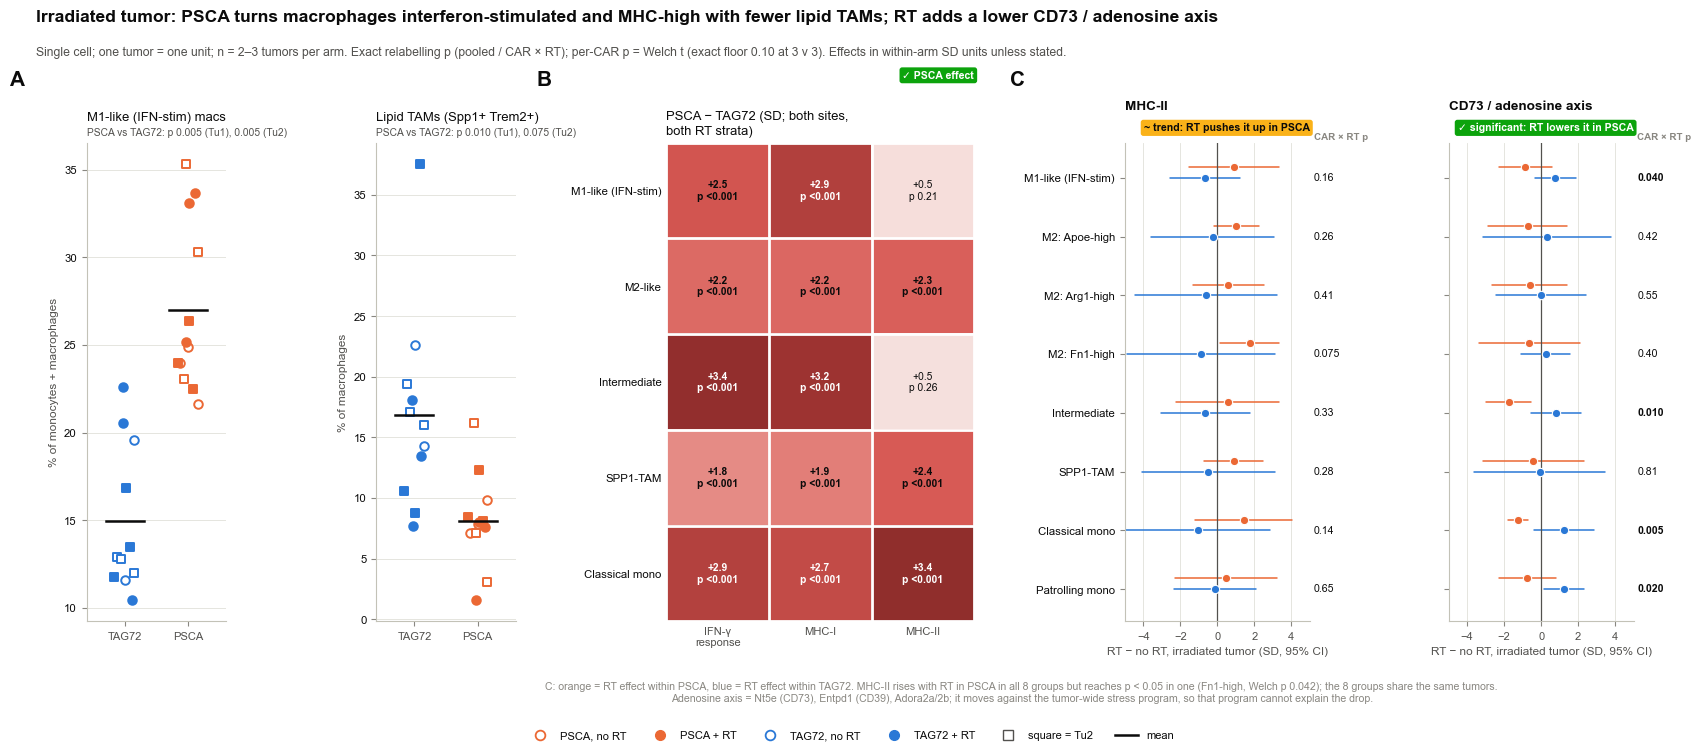

In [3]:
fig = plt.figure(figsize=(17, 7.6))
gs = GridSpec(1, 4, width_ratios=[0.52, 0.52, 1.15, 1.9], wspace=0.55, left=0.05, right=0.96, top=0.8, bottom=0.17)
fig.suptitle("Irradiated tumor: PSCA turns macrophages interferon-stimulated and MHC-high with fewer lipid TAMs; "
             "RT adds a lower CD73 / adenosine axis", x=0.02, y=0.975, ha="left", fontsize=12.6, weight="bold")
fig.text(0.02, 0.915, "Single cell; one tumor = one unit; n = 2–3 tumors per arm. Exact relabelling p (pooled / CAR × RT); "
         "per-CAR p = Welch t (exact floor 0.10 at 3 v 3). Effects in within-arm SD units unless stated.",
         fontsize=8.8, color=INK2)

# A: composition
ax = fig.add_subplot(gs[0])
p1, p2 = ceff("IFN_stimulated_Mac", "% of mono/mac", "PSCA Tu1", "pooled", "p"), ceff("IFN_stimulated_Mac", "% of mono/mac", "PSCA Tu2", "pooled", "p")
strip_car(ax, "IFN_stimulated_Mac | % of mono/mac", "% of monocytes + macrophages", "M1-like (IFN-stim) macs",
          f"PSCA vs TAG72: p {fmt_p(p1)} (Tu1), {fmt_p(p2)} (Tu2)")
ax.text(-0.55, 1.12, "A", transform=ax.transAxes, fontsize=15, weight="bold")
ax = fig.add_subplot(gs[1])
p1, p2 = ceff("Spp1_Trem2_high", "% of macrophages", "PSCA Tu1", "pooled", "p"), ceff("Spp1_Trem2_high", "% of macrophages", "PSCA Tu2", "pooled", "p")
strip_car(ax, "Spp1_Trem2_high | % of macrophages", "% of macrophages", "Lipid TAMs (Spp1+ Trem2+)",
          f"PSCA vs TAG72: p {fmt_p(p1)} (Tu1), {fmt_p(p2)} (Tu2)")

# B: PSCA program effects
ax = fig.add_subplot(gs[2]); ax.text(-0.42, 1.12, "B", transform=ax.transAxes, fontsize=15, weight="bold")
GB = ["IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "Classical_Mono"]
PB_ = [("IFNG_Hallmark", "IFN-γ\nresponse"), ("MHC_I_machinery", "MHC-I"), ("MHC_II_core", "MHC-II")]
V = pd.DataFrame({lab: [PSC[(PSC.effect == "PSCA") & (PSC.group == g) & (PSC.program == p)].main.iloc[0] for g in GB] for p, lab in PB_}, index=GB)
P = pd.DataFrame({lab: [PSC[(PSC.effect == "PSCA") & (PSC.group == g) & (PSC.program == p)].p_main.iloc[0] for g in GB] for p, lab in PB_}, index=GB)
ax.imshow(V.values, cmap=DIV, norm=TwoSlopeNorm(vmin=-4, vcenter=0, vmax=4), aspect="auto")
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        ax.text(j, i, f"{V.iat[i, j]:+.1f}\np {fmt_p(P.iat[i, j])}", ha="center", va="center", fontsize=7.4,
                color="white" if abs(V.iat[i, j]) > 2.6 else INK, weight="bold" if P.iat[i, j] < 0.05 else "normal")
ax.set_xticks(range(V.shape[1])); ax.set_xticklabels(V.columns, fontsize=8)
ax.set_yticks(range(len(GB))); ax.set_yticklabels([NAME[g] for g in GB])
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
ax.set_xticks(np.arange(-.5, V.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, V.shape[0]), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
ax.set_title("PSCA − TAG72 (SD; both sites,\nboth RT strata)", loc="left", fontsize=9.4)
badge(ax, "✓ PSCA effect", S_GOOD, y=1.13)

# C: RT within each CAR, Tu1 — MHC-II (trend) and adenosine (significant)
sub = GridSpecFromSubplotSpec(1, 2, gs[3], wspace=0.75)
GC = ["IFN_stimulated_Mac", "Apoe_high_Mac", "Arg1_high_Mac", "Fn1_high_Mac", "Intermediate_Mac", "SPP1_TAM", "Classical_Mono", "Nonclassical_Mono"]
for k, (module, title, status, color, tcol) in enumerate([("MHC-II presentation", "MHC-II", "~ trend: RT pushes it up in PSCA", S_WARN, INK),
                                                          ("Adenosine axis", "CD73 / adenosine axis", "✓ significant: RT lowers it in PSCA", S_GOOD, "white")]):
    ax = fig.add_subplot(sub[k])
    rows = []
    for g in GC:
        a, b, c = mod(g, module, "RT Tu1", "PSCA"), mod(g, module, "RT Tu1", "TAG72"), mod(g, module, "RT Tu1", "CARxRT")
        rows.append(dict(label=NAME[g], psca=(a.est, a.lo, a.hi), tag=(b.est, b.lo, b.hi), pooled=None,
                         p=fmt_p(c.p), bold=c.p < 0.05))
    forest(ax, rows, "RT − no RT, irradiated tumor (SD, 95% CI)", p_head="CAR × RT p", xlim=(-5, 5))
    if k: ax.set_yticklabels([])
    ax.set_title(title, loc="left", fontsize=9.8, pad=24, weight="bold")
    badge(ax, status, color, tc=tcol, y=1.02)
    if k == 0: ax.text(-0.62, 1.12, "C", transform=ax.transAxes, fontsize=15, weight="bold")
fig.text(0.6, 0.065, "C: orange = RT effect within PSCA, blue = RT effect within TAG72. MHC-II rises with RT in PSCA in all 8 groups "
         "but reaches p < 0.05 in one (Fn1-high, Welch p 0.042); the 8 groups share the same tumors.\nAdenosine axis = Nt5e (CD73), "
         "Entpd1 (CD39), Adora2a/2b; it moves against the tumor-wide stress program, so that program cannot explain the drop.",
         fontsize=7.6, color=MUTED, ha="center")
legend(fig, y=0.0)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureS1_irradiated_summary.{ext}", bbox_inches="tight")
plt.show()

## Figure S2 — abscopal tumor

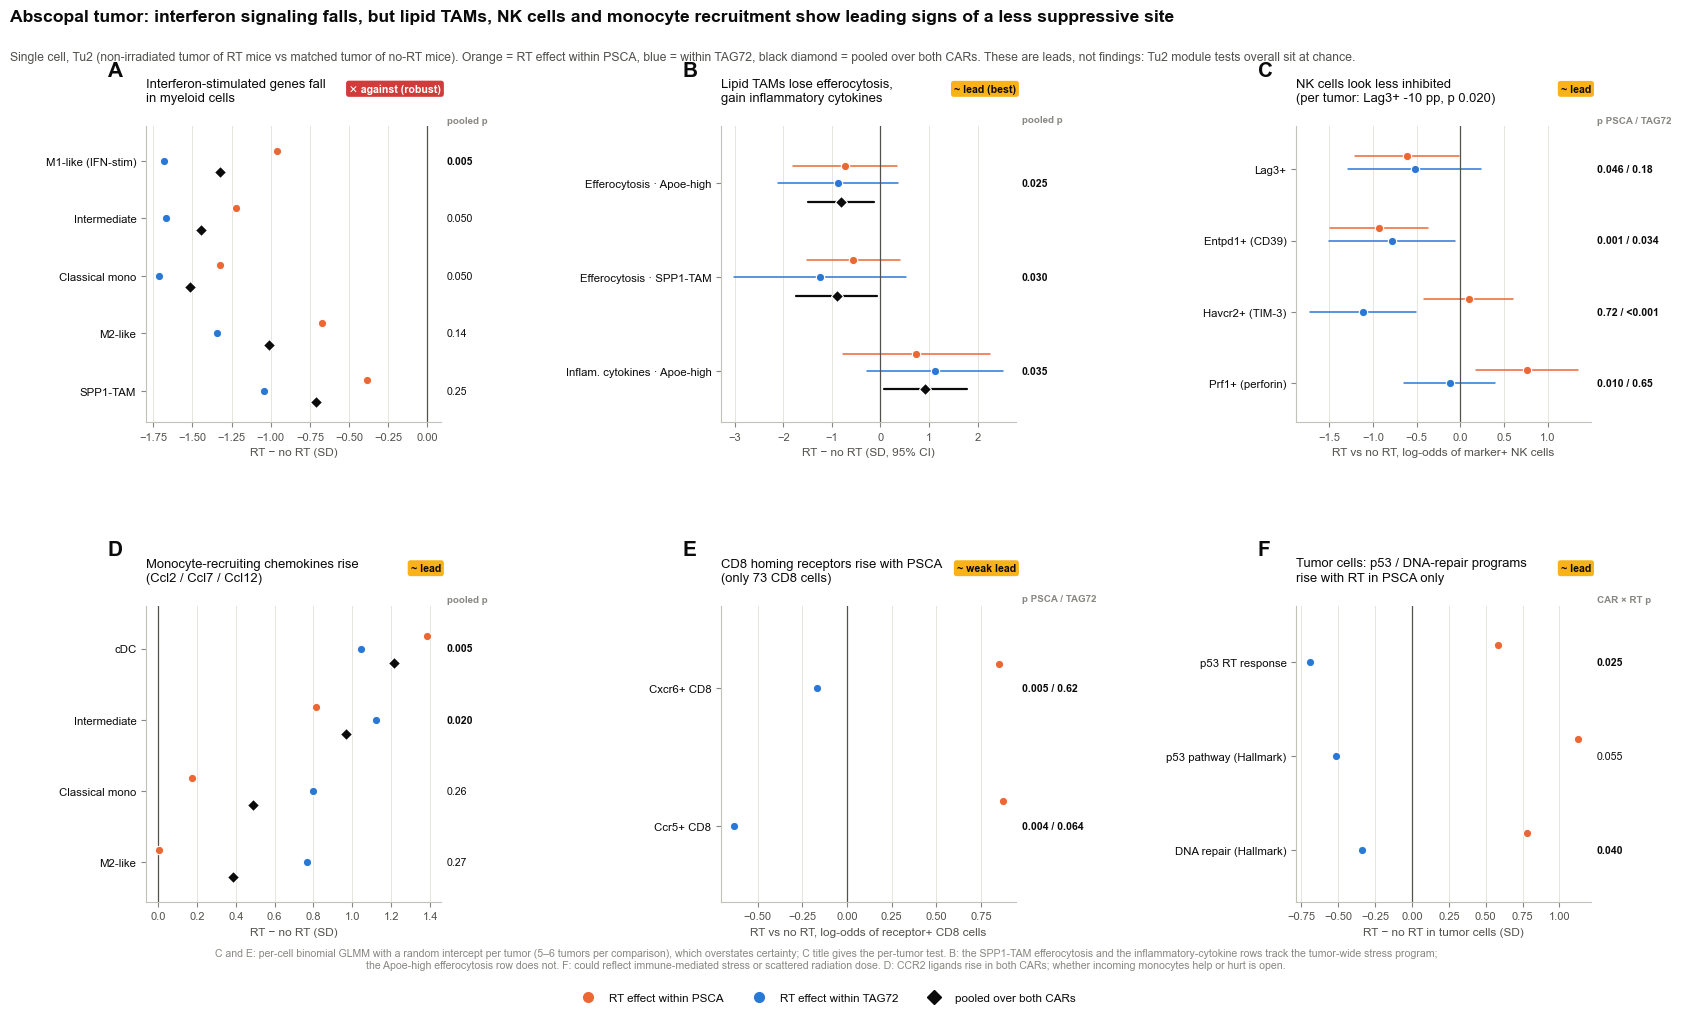

[files] /Users/janzules/Roselab/Spatial/CAR_T/results/rt_advantage/specific_cell_type/summary


In [4]:
fig = plt.figure(figsize=(17, 10.2))
gs = GridSpec(2, 3, hspace=0.62, wspace=0.95, left=0.1, right=0.95, top=0.86, bottom=0.1)
fig.suptitle("Abscopal tumor: interferon signaling falls, but lipid TAMs, NK cells and monocyte recruitment show leading "
             "signs of a less suppressive site", x=0.02, y=0.975, ha="left", fontsize=12.6, weight="bold")
fig.text(0.02, 0.925, "Single cell, Tu2 (non-irradiated tumor of RT mice vs matched tumor of no-RT mice). Orange = RT effect within PSCA, "
         "blue = within TAG72, black diamond = pooled over both CARs. These are leads, not findings: Tu2 module tests overall "
         "sit at chance.", fontsize=8.8, color=INK2)


def ps_rows(groups, program, eff="indirect RT"):
    out = []
    for g in groups:
        r = PSC[(PSC.effect == eff) & (PSC.group == g) & (PSC.program == program)].iloc[0]
        out.append(dict(label=NAME[g], psca=(r.d_PSCA, np.nan, np.nan), tag=(r.d_TAG72, np.nan, np.nan),
                        pooled=(r.main, np.nan, np.nan), p=fmt_p(r.p_main), bold=r.p_main < 0.05))
    return out


# A: against — ISG loss
ax = fig.add_subplot(gs[0, 0])
forest(ax, ps_rows(["IFN_stimulated_Mac", "Intermediate_Mac", "Classical_Mono", "M2_like_Mac", "SPP1_TAM"], "ISG_core"),
       "RT − no RT (SD)", p_head="pooled p")
ax.set_title("Interferon-stimulated genes fall\nin myeloid cells", loc="left", fontsize=9.4, pad=18)
badge(ax, "✕ against (robust)", S_CRIT, y=1.11); ax.text(-0.13, 1.17, "A", transform=ax.transAxes, fontsize=15, weight="bold")

# B: lipid TAMs
ax = fig.add_subplot(gs[0, 1]); rows = []
for g, m, lab in [("Apoe_high_Mac", "Efferocytosis", "Efferocytosis · Apoe-high"), ("SPP1_TAM", "Efferocytosis", "Efferocytosis · SPP1-TAM"),
                  ("Apoe_high_Mac", "Inflammatory cytokines", "Inflam. cytokines · Apoe-high")]:
    a, b, c = mod(g, m, "RT Tu2", "PSCA"), mod(g, m, "RT Tu2", "TAG72"), mod(g, m, "RT Tu2", "pooled")
    rows.append(dict(label=lab, psca=(a.est, a.lo, a.hi), tag=(b.est, b.lo, b.hi), pooled=(c.est, c.lo, c.hi),
                     p=fmt_p(c.p), bold=c.p < 0.05))
forest(ax, rows, "RT − no RT (SD, 95% CI)", p_head="pooled p")
ax.set_title("Lipid TAMs lose efferocytosis,\ngain inflammatory cytokines", loc="left", fontsize=9.4, pad=18)
badge(ax, "~ lead (best)", S_WARN, tc=INK, y=1.11); ax.text(-0.13, 1.17, "B", transform=ax.transAxes, fontsize=15, weight="bold")

# C: NK cells
ax = fig.add_subplot(gs[0, 2]); rows = []
for mk in ["Lag3+", "Entpd1+", "Havcr2+", "Prf1+"]:
    a = EXG[(EXG["pop"] == "NK") & (EXG.comparison == "indirect RT PSCA") & (EXG.marker == mk)].iloc[0]
    b = EXG[(EXG["pop"] == "NK") & (EXG.comparison == "indirect RT TAG72") & (EXG.marker == mk)].iloc[0]
    rows.append(dict(label={"Lag3+": "Lag3+", "Entpd1+": "Entpd1+ (CD39)", "Havcr2+": "Havcr2+ (TIM-3)", "Prf1+": "Prf1+ (perforin)"}[mk],
                     psca=(a.logodds, a.logodds - 1.96 * a.sd, a.logodds + 1.96 * a.sd),
                     tag=(b.logodds, b.logodds - 1.96 * b.sd, b.logodds + 1.96 * b.sd), pooled=None,
                     p=f"{fmt_p(a.p)} / {fmt_p(b.p)}", bold=min(a.p, b.p) < 0.05))
forest(ax, rows, "RT vs no RT, log-odds of marker+ NK cells", p_head="p PSCA / TAG72")
lag = EXS[(EXS["pop"] == "NK") & (EXS.measure == "Lag3+") & (EXS.effect == "indirect RT")].iloc[0]
ax.set_title(f"NK cells look less inhibited\n(per tumor: Lag3+ {lag.main * 100:+.0f} pp, p {fmt_p(lag.p_main)})", loc="left", fontsize=9.4, pad=18)
badge(ax, "~ lead", S_WARN, tc=INK, y=1.11); ax.text(-0.13, 1.17, "C", transform=ax.transAxes, fontsize=15, weight="bold")

# D: monocyte recruitment
ax = fig.add_subplot(gs[1, 0])
forest(ax, ps_rows(["cDC", "Intermediate_Mac", "Classical_Mono", "M2_like_Mac"], "CCR2_ligands"), "RT − no RT (SD)", p_head="pooled p")
ax.set_title("Monocyte-recruiting chemokines rise\n(Ccl2 / Ccl7 / Ccl12)", loc="left", fontsize=9.4, pad=18)
badge(ax, "~ lead", S_WARN, tc=INK, y=1.11); ax.text(-0.13, 1.17, "D", transform=ax.transAxes, fontsize=15, weight="bold")

# E: CD8 homing receptors
ax = fig.add_subplot(gs[1, 1]); rows = []
for rc in ["Cxcr6", "Ccr5"]:
    a = CRG[(CRG.target == "CD8_T") & (CRG.receptor == rc) & (CRG.comparison == "indirect RT PSCA")].iloc[0]
    b = CRG[(CRG.target == "CD8_T") & (CRG.receptor == rc) & (CRG.comparison == "indirect RT TAG72")].iloc[0]
    rows.append(dict(label=f"{rc}+ CD8", psca=(a.logodds, np.nan, np.nan), tag=(b.logodds, np.nan, np.nan), pooled=None,
                     p=f"{fmt_p(a.p)} / {fmt_p(b.p)}", bold=min(a.p, b.p) < 0.05))
forest(ax, rows, "RT vs no RT, log-odds of receptor+ CD8 cells", p_head="p PSCA / TAG72")
ax.set_title(f"CD8 homing receptors rise with PSCA\n(only {int(a.n_cells)} CD8 cells)", loc="left", fontsize=9.4, pad=18)
badge(ax, "~ weak lead", S_WARN, tc=INK, y=1.11); ax.text(-0.13, 1.17, "E", transform=ax.transAxes, fontsize=15, weight="bold")

# F: tumor cells
ax = fig.add_subplot(gs[1, 2]); rows = []
for prog, lab in [("p53_RT_response", "p53 RT response"), ("p53_H", "p53 pathway (Hallmark)"), ("DNA_repair_H", "DNA repair (Hallmark)")]:
    r = TST[(TST.site == 2) & (TST.program == prog)].iloc[0]
    rows.append(dict(label=lab, psca=(r.d_PSCA, np.nan, np.nan), tag=(r.d_TAG72, np.nan, np.nan), pooled=None,
                     p=fmt_p(r.p_inter), bold=r.p_inter < 0.05))
forest(ax, rows, "RT − no RT in tumor cells (SD)", p_head="CAR × RT p")
ax.set_title("Tumor cells: p53 / DNA-repair programs\nrise with RT in PSCA only", loc="left", fontsize=9.4, pad=18)
badge(ax, "~ lead", S_WARN, tc=INK, y=1.11); ax.text(-0.13, 1.17, "F", transform=ax.transAxes, fontsize=15, weight="bold")

fig.text(0.5, 0.035, "C and E: per-cell binomial GLMM with a random intercept per tumor (5–6 tumors per comparison), which "
         "overstates certainty; C title gives the per-tumor test. B: the SPP1-TAM efferocytosis and the inflammatory-cytokine "
         "rows track the tumor-wide stress program;\nthe Apoe-high efferocytosis row does not. F: could reflect immune-mediated "
         "stress or scattered radiation dose. D: CCR2 ligands rise in both CARs; whether incoming monocytes help or hurt is open.",
         fontsize=7.6, color=MUTED, ha="center")
legend_h = [Line2D([], [], marker="o", ls="", color=C_PSCA, ms=7, label="RT effect within PSCA"),
            Line2D([], [], marker="o", ls="", color=C_TAG72, ms=7, label="RT effect within TAG72"),
            Line2D([], [], marker="D", ls="", color=INK, ms=7, label="pooled over both CARs")]
fig.legend(handles=legend_h, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01), fontsize=8.4)
for ext in ("png", "pdf"): fig.savefig(OUT/f"FigureS2_abscopal_leads.{ext}", bbox_inches="tight")
plt.show()
print(f"[files] {OUT}")